In [32]:
%pip install -U langgraph


In [55]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [66]:
class BMIState(TypedDict):
  weight_kg:float
  height_m:float
  bmi:float
  category: str


In [67]:
def calculate_bmi(state: BMIState) -> BMIState:
  weight=state['weight_kg']
  height=state['height_m']
  bmi=weight/(height**2)
  state['bmi']=round(bmi,2)
  return state


In [71]:
def labelBMI(state:BMIState) -> BMIState:
  bmi=state['bmi']
  if bmi<18.5:
    state['category']='Underweight'
  elif bmi<25:
    state['category']='Normal'
  elif bmi>25 and bmi<30:
    state['category']='Overweight'
  else:
    state['category']='Obese'
  return state

In [72]:
graph=StateGraph(BMIState)
graph.add_node('calculate_bmi',calculate_bmi)
graph.add_node('labelBMI',labelBMI)
graph.add_edge(START,'calculate_bmi')
graph.add_edge('calculate_bmi','labelBMI')
graph.add_edge('labelBMI',END)
workflow=graph.compile()



In [73]:
initial_state={'weight_kg':80,'height_m':1.76}
final_state=workflow.invoke(initial_state)
print(final_state)

{'weight_kg': 80, 'height_m': 1.76, 'bmi': 25.83, 'category': 'Overweight'}


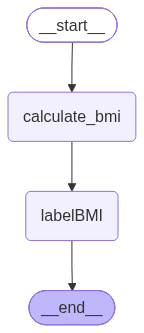

In [74]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())